# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import AIDERDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/AIDER/",
    "csv_file": "./data/AIDER/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = AIDERDataset(dataset_config)

## Show images from the dataset

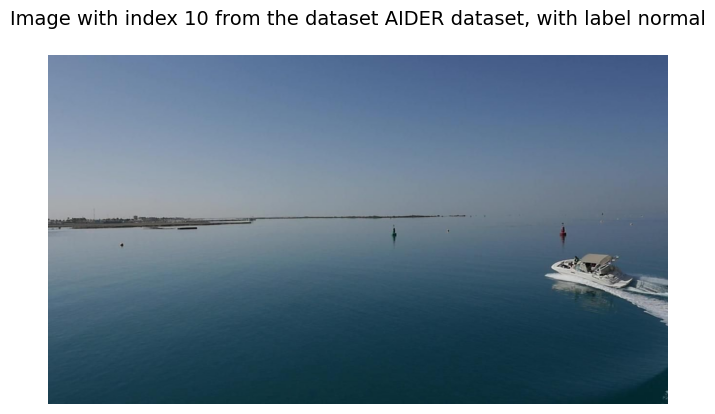

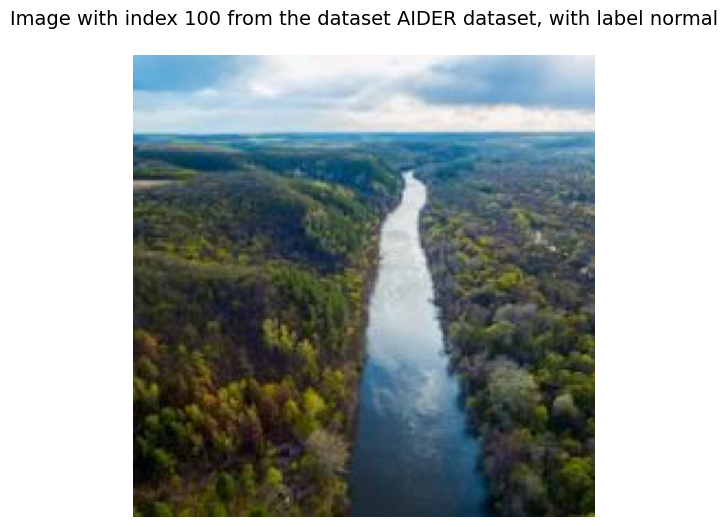

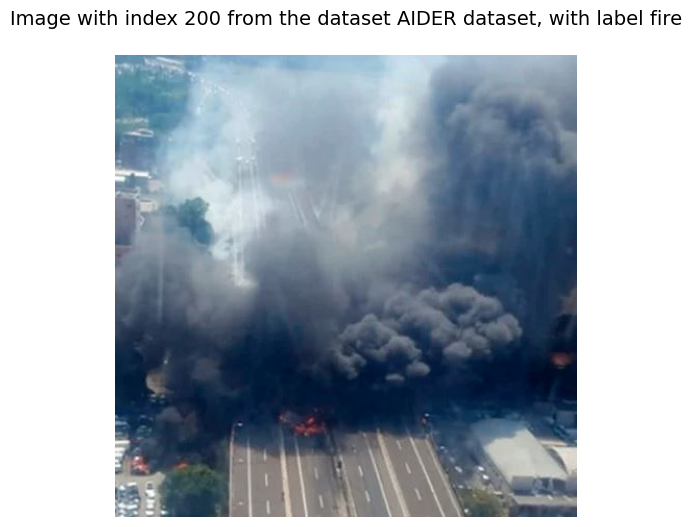

In [6]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(100)
fig3 = dataset.show_image(200)

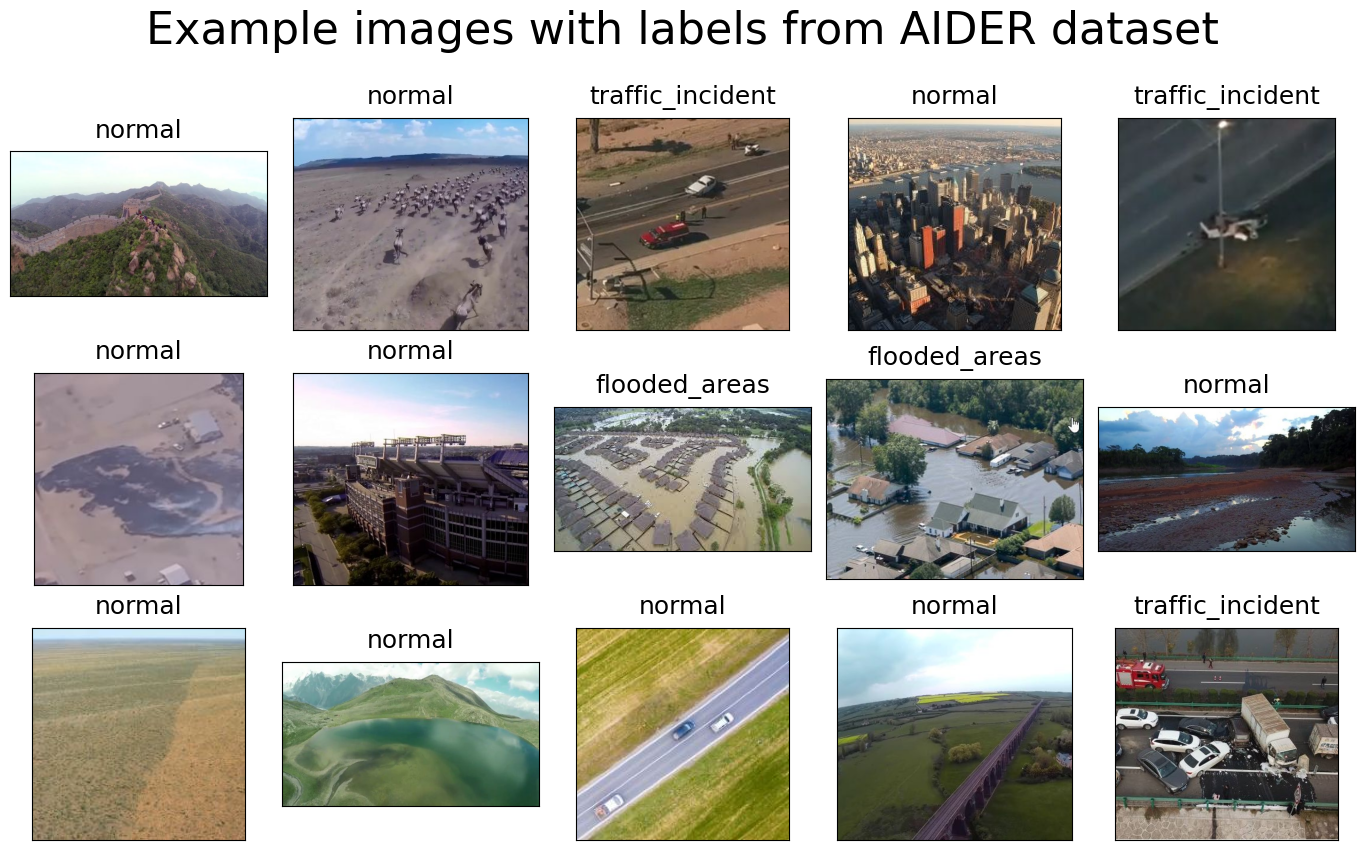

In [7]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [8]:
dataset.show_samples()

,File name,Label
0,traffic_incident/traffic_incident_image0102.jpg,traffic_incident
1,normal/normal_image2953.jpg,normal
2,normal/normal_image0763.jpg,normal
3,normal/normal_image1164.jpg,normal
4,collapsed_building/collapsed_building_image017...,collapsed_building
5,normal/normal_image4221.jpg,normal
6,normal/normal_image4258.jpg,normal
7,collapsed_building/collapsed_building_image041...,collapsed_building
8,normal/normal_image2192.jpg,normal
9,normal/normal_image3834.jpg,normal


In [9]:
dataset.data_distribution_table()

,Label,Count
0,collapsed_building,394
1,fire,409
2,flooded_areas,410
3,normal,3544
4,traffic_incident,390


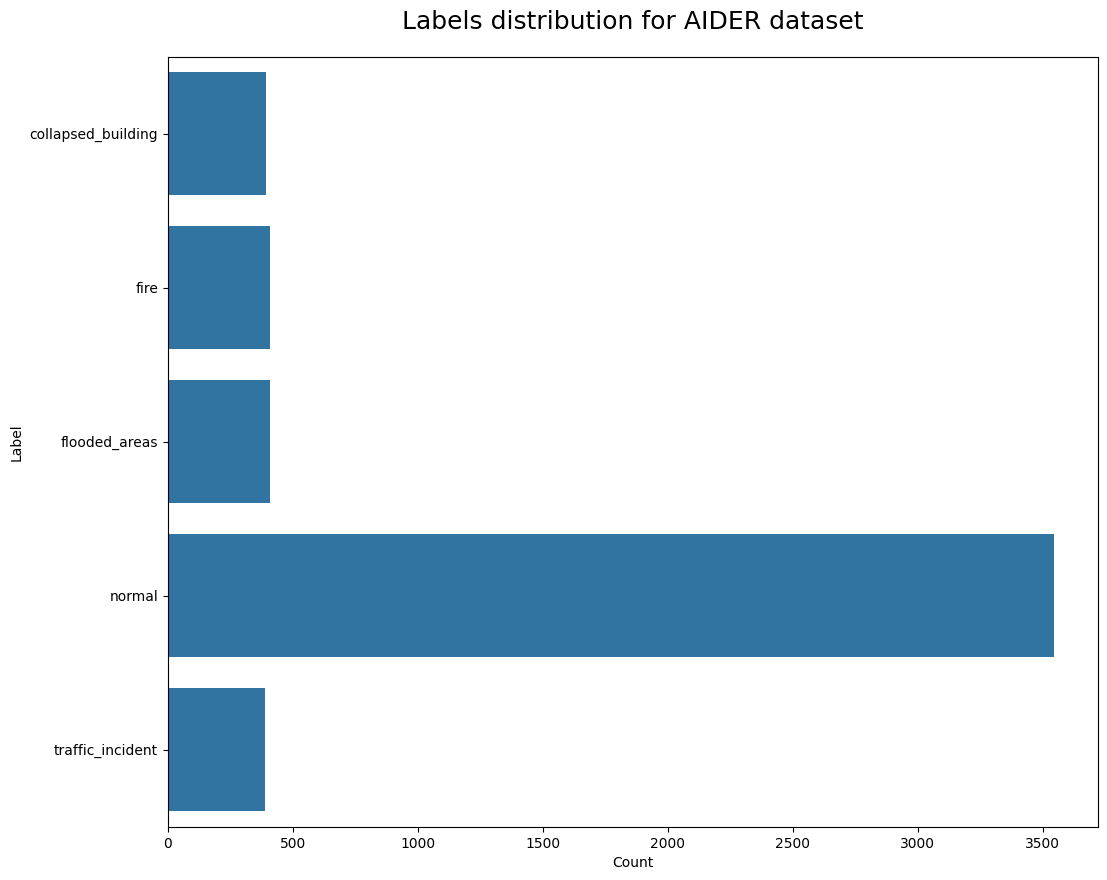

In [10]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/AIDER/",
    "csv_file": "./data/AIDER/train.csv",
}

train_dataset = AIDERDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/AIDER/",
    "csv_file": "./data/AIDER/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = AIDERDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(5147, 643)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/AIDER/"
model_config = {
    "num_classes": 5, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-28 12:27:06,210 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-28 12:27:06,388 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [6]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-28 12:27:07,936 INFO Starting training.
training: 100%|██████████| 161/161 [01:40<00:00,  1.61it/s]
2025-05-28 12:28:48,212 INFO epoch: 1, time: 100, loss:  0.38767
testing on train set: 100%|██████████| 161/161 [00:36<00:00,  4.44it/s]
2025-05-28 12:29:26,637 INFO Accuracy:0.9743539926170585, Precision Micro:0.9743539926170585, Precision Macro:0.9473192529929723, Precision Weighted:0.9757146364925444, Precision per Class:[0.95093458 0.95035461 0.87024609 0.9713467  0.99371429], Recall Micro:0.9743539926170585, Recall Macro:0.9627030436796093, Recall Weighted:0.9743539926170586, Recall per Class:[0.99511002 0.9804878  0.98730964 0.86923077 0.98137698], F1_score Micro:0.9743539926170579, F1_score Macro:0.9535518563746443, F1_score Weighted:0.9744522019112585, F1_score per Class:[0.97252091 0.96518607 0.92508918 0.91745602 0.9875071 ]
testing on validation set: 100%|██████████| 21/21 [00:04<00:00,  4.29it/s]
2025-05-28 12:29:31,547 INFO Accuracy:0.9626749611197511, Precision Micr

0.0033016984643159846

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/AIDER/",
    "csv_file": "./data/AIDER/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = AIDERDataset(test_dataset_config)
model_path = "./data/experiments/AIDER/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-28 12:51:20,622 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/AIDER/checkpoint.pth.tar
2025-05-28 12:51:21,551 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/AIDER/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 41/41 [00:05<00:00,  6.97it/s]


[{'Accuracy': 0.9844479004665629},
 {'Precision Micro': 0.9844479004665629,
  'Precision Macro': 0.9655513331057761,
  'Precision Weighted': 0.9847493187588213,
  'Precision per Class': array([0.96666667, 1.        , 0.93617021, 0.92727273, 0.99764706])},
 {'Recall Micro': 0.9844479004665629,
  'Recall Macro': 0.9778622343839736,
  'Recall Weighted': 0.9844479004665629,
  'Recall per Class': array([1.        , 1.        , 0.95652174, 0.94444444, 0.98834499])},
 {'F1_score Micro': 0.9844479004665625,
  'F1_score Macro': 0.9716082923974098,
  'F1_score Weighted': 0.9845441515434945,
  'F1_score per Class': array([0.98305085, 1.        , 0.94623656, 0.93577982, 0.99297424])}]

## Predictions

2025-05-28 12:53:51,232 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/AIDER/checkpoint.pth.tar
2025-05-28 12:53:52,118 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/AIDER/checkpoint.pth.tar at epoch 11


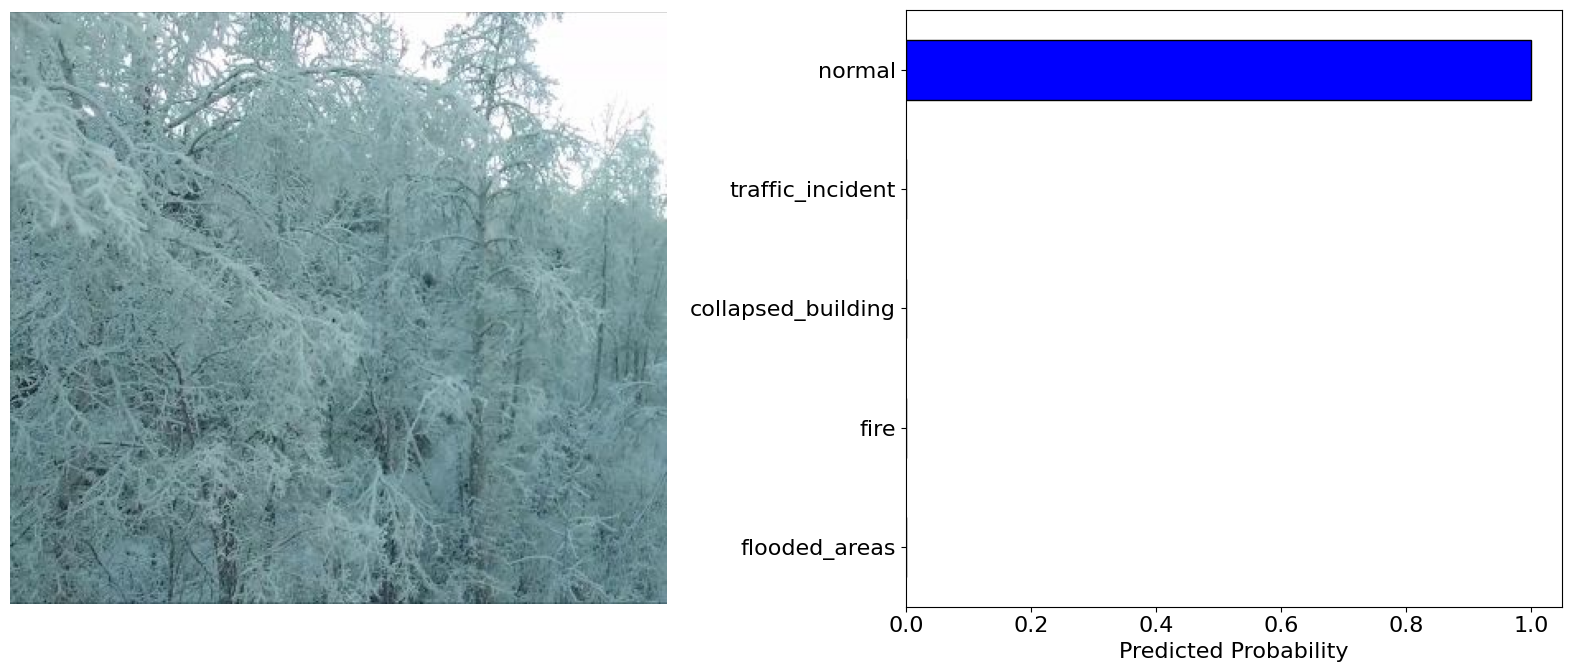

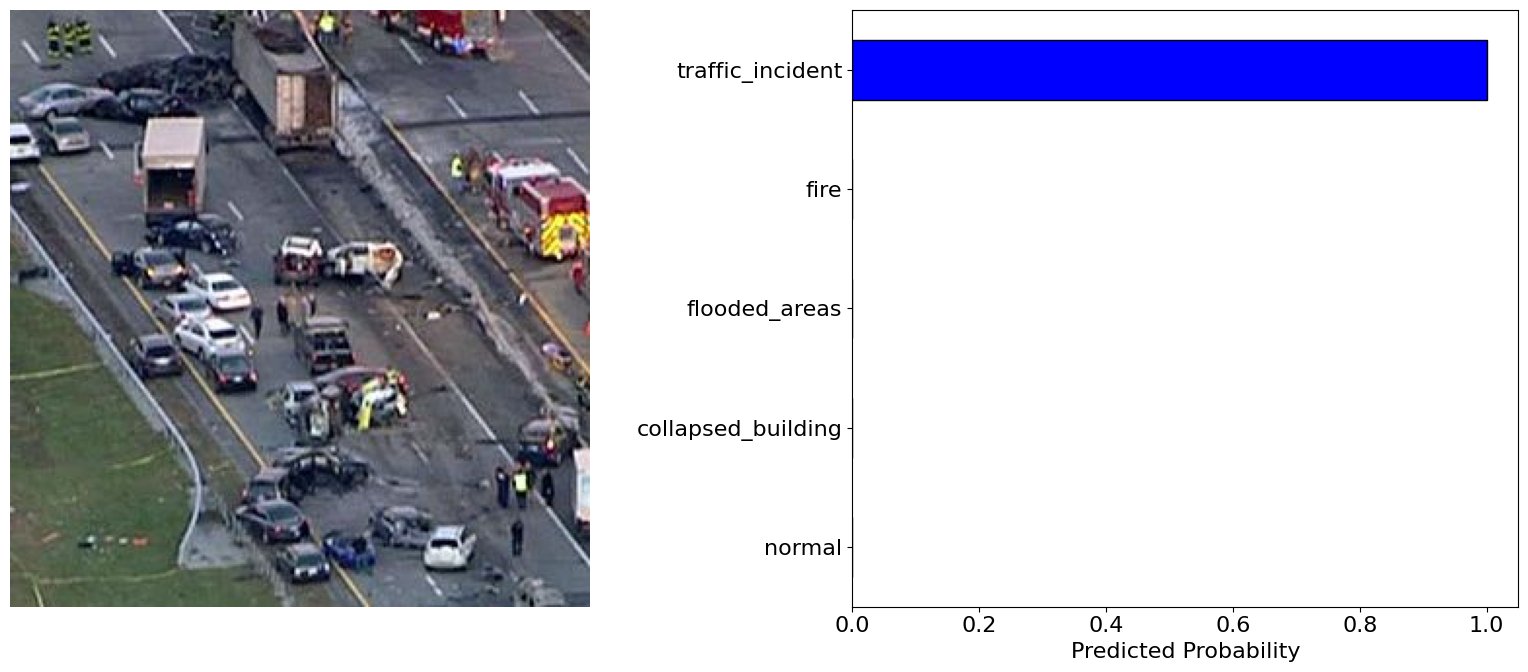

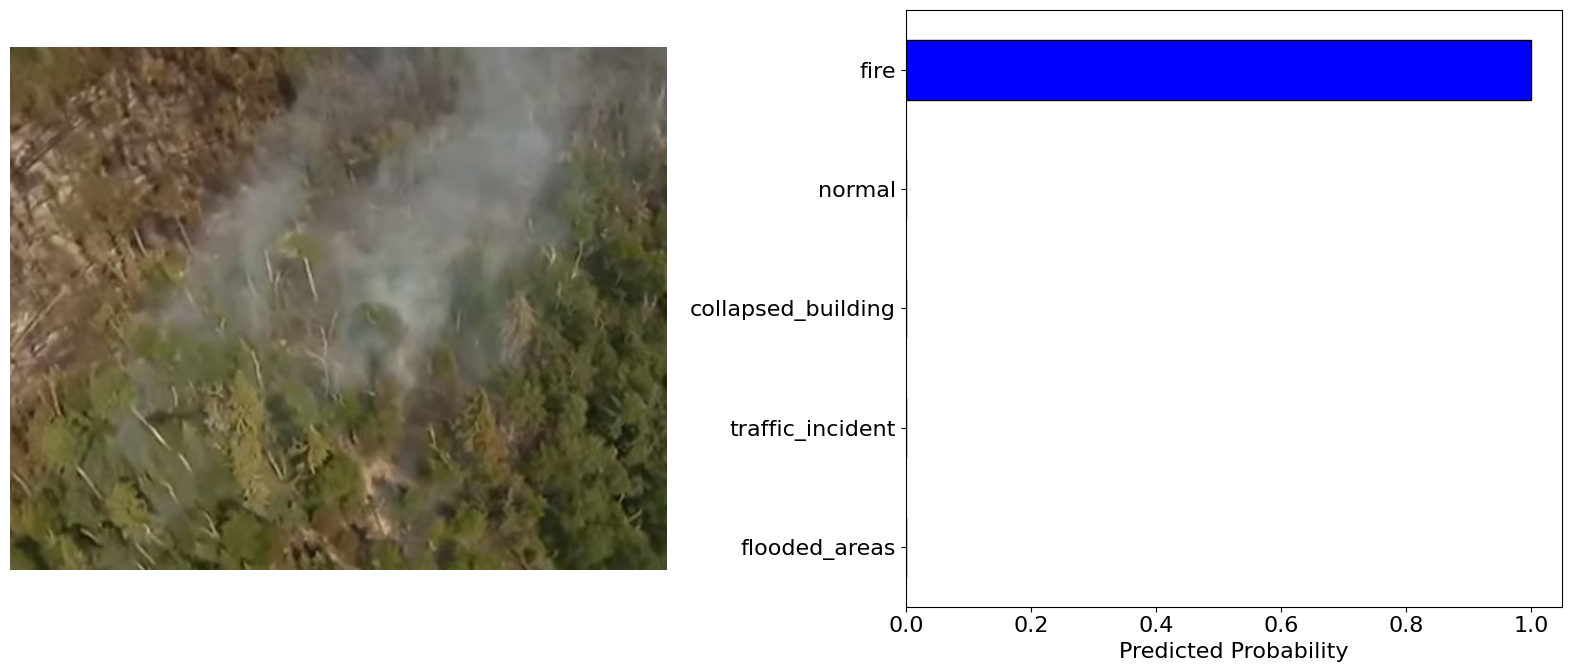

In [ ]:
labels = ["fire", "flooded_areas", "collapsed_building", "traffic_incident","normal"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/AIDER/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/AIDER/normal/normal_image4185.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/AIDER/traffic_incident/traffic_incident_image0025.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/AIDER/fire/fire_image0146.jpg')
fig = model.predict_image(image, labels, transform)